In [1]:
from multi_func import *
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import numpy as np
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
import os
os.makedirs('results', exist_ok=True)
D='cuda' if torch.cuda.is_available() else 'cpu'
print(D)

cpu


In [3]:
bs = 32
LR = 1e-3
epoch = 5
cri = nn.CrossEntropyLoss()
nmt = True
mty = "CNN"
dset = "CIFAR10"
smp = f"results/{mty}_{dset}.pt"

In [59]:
def sq(x):
    return x**2

In [ ]:
trtr = transforms.Compose(
    [
        # 이미지 크기 및 영역 조절
        # transforms.Resize(size=(20, 20)),
        # transforms.CenterCrop(size=(20, 20)),
        # transforms.RandomCrop(size=(20, 20)),
        # transforms.Pad(6),
        # 조건부 이미지 변환
        # transforms.RandomApply(
        #     nn.ModuleList([transforms.CenterCrop(size=(20, 20)), transforms.Pad(6)]),
        #     p=0.5,
        # ),
        # transforms.RandomResizedCrop(size=(32, 32), scale=(0.3, 1), ratio=(0.3, 1.7)),
        # 색상 및 밝기 변환
        # transforms.RandomGrayscale(p=0.5),
        # transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.5, hue=0.15),
        # transforms.RandomAutocontrast(p=0.5),
        # transforms.RandomEqualize(p=0.5),
        # transforms.RandomInvert(p=0.5),
        # transforms.RandomSolarize(threshold=200, p=0.5),
        # transforms.RandomPosterize(bits=3, p=0.5),
        # 선명도 및 흐림 정도
        # transforms.GaussianBlur(kernel_size=(5, 5), sigma=(0.1, 2)),
        # transforms.RandomAdjustSharpness(sharpness_factor=2, p=0.5),
        # 방향 및 위치 변환
        # transforms.RandomHorizontalFlip(p=0.5),
        # transforms.RandomVerticalFlip(p=0.5),
        # transforms.RandomRotation(degrees=(0, 180)),
        # transforms.RandomAffine(degrees=(0, 30), translate=(0.1, 0.3), scale=(0.5, 1.2)),
        # transforms.RandomPerspective(distortion_scale=0.6, p=0.5),
        # 자동 데이터 증강
        # transforms.AutoAugment(transforms.AutoAugmentPolicy.CIFAR10),
        # transforms.RandAugment(),
        # transforms.TrivialAugmentWide(),
        # transforms.AugMix(),
        # transforms.RandomErasing(p=0.5, scale=(0.03, 0.3), ratio=(0.3, 3.3)),
        transforms.ToTensor(),
        # 사용자 정의 함수
        # transforms.Lambda(sq),
        # 정규화
        transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225)),
    ]
)
trts = transforms.ToTensor()
trds = datasets.CIFAR10(root="data", train=True, download=False, transform=trtr)
teds = datasets.CIFAR10(root="data", train=False, download=False, transform=trts)
trdl = DataLoader(trds, batch_size=bs, shuffle=True)
tedl = DataLoader(teds, batch_size=bs, shuffle=True)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.7925336..2.5702832].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.0836544..2.3088455].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-1.980906..2.64].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.1007793..2.4831376].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.5702832].


img size=torch.Size([3, 32, 32])
img size=torch.Size([3, 32, 32])


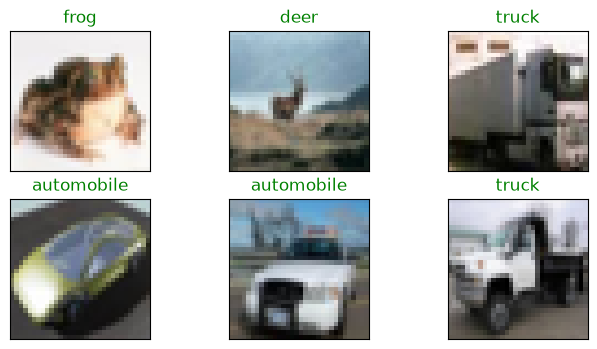

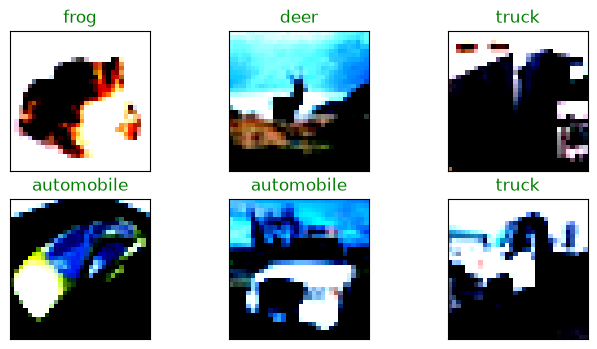

In [68]:
from PIL import Image


def imgp(x, y, t):
    plt.figure(figsize=(8, 4))
    for i in range(6):
        im = Image.fromarray(x[i])
        im = t(im)
        plt.subplot(2, 3, i + 1, xticks=[], yticks=[])
        plt.imshow(im.permute(1, 2, 0))
        tc = teds.classes[int(y[i])]
        plt.title(tc, color="g")
    print(f"img size={im.shape}")


idx = torch.randint(0, 10000, (6,))
x_batch = teds.data[idx]
tg = torch.tensor(teds.targets)
y_batch = tg[idx]
imgp(x_batch, y_batch, trts)
imgp(x_batch, y_batch, trtr)

#### dropout
: 오버피팅 되었을 때 학습에서 10~30% 내외로 비활성화, 그만큼 학습이 덜 돼서 오버피팅 막음

In [69]:
du = nn.Dropout(p=0.3)
x = torch.randint(1, 101, (10,)).float()
print("원본:", x)
print("원본 합계:", x.sum())

원본: tensor([63., 73., 81., 81., 65., 84., 92., 23., 84., 89.])
원본 합계: tensor(735.)


In [72]:
du.train()
t1 = du(x)
print(t1)
print(t1.sum())
t2 = du(x)
print(t2)
print(t2.sum())
t3 = du(x)
print(t3)
print(t3.sum())

du.eval()
t1 = du(x)
print(t1)

tensor([ 90.0000, 104.2857, 115.7143,   0.0000,  92.8571, 120.0000, 131.4286,
         32.8571, 120.0000, 127.1429])
tensor(934.2857)
tensor([ 90.0000, 104.2857, 115.7143, 115.7143,  92.8571, 120.0000,   0.0000,
          0.0000, 120.0000, 127.1429])
tensor(885.7142)
tensor([ 90.0000,   0.0000, 115.7143, 115.7143,   0.0000, 120.0000, 131.4286,
         32.8571, 120.0000, 127.1429])
tensor(852.8571)
tensor([63., 73., 81., 81., 65., 84., 92., 23., 84., 89.])


In [73]:
class sm(nn.Module):
    def __init__(self):
        super().__init__()
        self.dl = nn.Sequential(nn.Linear(5, 7), nn.ReLU(), nn.Dropout(p=0.2))

    def forward(self, x):
        x = self.dl(x)
        return x


m = sm()
m.train()
x = torch.randn(2, 3, 5)
print(x)
print(m(x))

tensor([[[ 0.1887,  1.9015,  1.1361,  0.1215, -0.2300],
         [-0.7095, -0.1476, -0.1522, -0.2435,  1.5075],
         [ 0.4637,  1.1320,  0.9501,  1.0218,  0.5904]],

        [[-0.5012, -0.0472,  1.6152,  0.1668, -1.0639],
         [-1.4671,  0.6372, -0.4100, -0.7218, -1.0490],
         [-0.8458,  0.5479,  0.1965,  0.1711,  1.8796]]])
tensor([[[0.0000, 0.6647, 0.0000, 0.0000, 0.0000, 0.6775, 0.0000],
         [0.5490, 0.4049, 0.0000, 0.0000, 0.0000, 0.7261, 0.0000],
         [0.0000, 0.0000, 0.2723, 0.0000, 0.0000, 0.0000, 0.0000]],

        [[1.2240, 1.5157, 1.1397, 0.0000, 0.6884, 0.2041, 0.8300],
         [0.5180, 1.2500, 0.0000, 0.0000, 0.0000, 0.8658, 0.3006],
         [0.5017, 0.1633, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000]]],
       grad_fn=<MulBackward0>)


In [74]:
class sm(nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.dl = nn.Sequential(nn.Conv2d(3, 3, 3), nn.Dropout2d(p=0.3))

    def forward(self, x):
        x = self.dl(x)
        return x


m = sm()
m.train()
x = torch.randn(5, 3, 4, 4)
print(m(x))

tensor([[[[ 0.3782,  0.9171],
          [-0.0415,  1.2640]],

         [[-0.0000,  0.0000],
          [-0.0000, -0.0000]],

         [[-1.0733, -1.1023],
          [ 1.1982, -0.5117]]],


        [[[-0.6127,  0.0510],
          [ 0.0076, -1.1608]],

         [[-0.2305,  0.1743],
          [-0.8899,  0.8381]],

         [[ 0.0961, -0.0598],
          [ 0.7259,  0.7465]]],


        [[[ 0.0000, -0.0000],
          [-0.0000, -0.0000]],

         [[-1.3106,  0.0918],
          [ 0.2591,  0.3735]],

         [[ 0.0000,  0.0000],
          [-0.0000, -0.0000]]],


        [[[ 0.7179, -1.8193],
          [ 0.0176,  0.2970]],

         [[ 0.1020,  0.9538],
          [ 0.5286,  0.0752]],

         [[-0.7090, -0.8821],
          [ 0.3414, -0.3034]]],


        [[[-0.8408, -0.1069],
          [-1.9618,  0.1897]],

         [[ 0.4960, -0.6351],
          [ 0.0789, -0.5362]],

         [[-1.1834, -0.2625],
          [-0.0852,  0.2923]]]], grad_fn=<MulBackward0>)
